# MNIST Digits Classification Problem

## Bussiness understanding

## Data Collection

### Import neceasary libraries

In [70]:
import keras
import pandas as pd
from matplotlib import pyplot as plt
from keras import Sequential
from keras.layers import Flatten,Dense
import numpy as np
from PIL import Image
from keras.models import load_model

In [8]:
 # Data available in the keras website .we can download it from there 

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
assert x_train.shape == (60000, 28, 28)
assert x_test.shape == (10000, 28, 28)
assert y_train.shape == (60000,)
assert y_test.shape == (10000,)


## Data understanding

In [9]:
# verify one random image
x_train[6889]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  

In [15]:
# Convert into a Dataframe to get better understanding

pd.set_option("display.max_columns",30)
pd.DataFrame(x_train[6889])

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,0,0,0,45,173,85,50,128,85,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,84,127,83,127,215,253,252,244,252,252,233,197,127,51,0,0,0,0,0
9,0,0,0,0,0,0,0,0,141,253,252,252,252,252,253,126,93,205,252,253,252,252,231,81,0,0,0,0


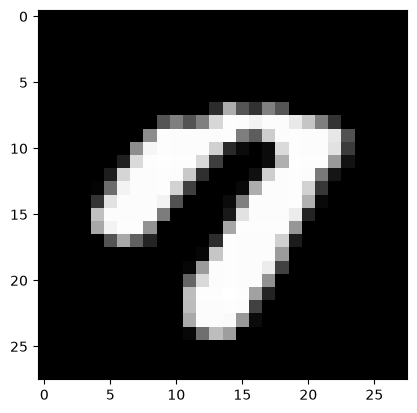

In [22]:
# Covert this into a image format and visualize

plt.imshow(x_train[6889] , cmap = "grey")
plt.show()

## Data Preparation

In [25]:
# Let's normalize the values for faster processing

# Find min and max values

x_train.min(), x_train.max()

(np.uint8(0), np.uint8(255))

In [30]:
# Apply the normalization method since all images are in a fixed range

x_train_final = x_train/255.0
x_test_final = x_test/255.0

In [31]:
# verify the sixe now 

x_train_final.min() ,x_train_final.max(), x_test_final.min(),x_test_final.max()

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

## Model Building

In [49]:
model = Sequential()
model.add(layer=Flatten())
model.add(Dense(units=100,activation="relu"))
model.add(Dense(units=10,activation="softmax"))
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [50]:
## Model Compilation

model.compile(optimizer="rmsprop",loss="sparse_categorical_crossentropy",metrics=["sparse_categorical_accuracy"])

In [51]:
model.fit(x=x_train_final,y=y_train,batch_size=128,epochs=4,validation_data=(x_test_final,y_test))

Epoch 1/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3507 - sparse_categorical_accuracy: 0.9056 - val_loss: 0.2020 - val_sparse_categorical_accuracy: 0.9423
Epoch 2/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1719 - sparse_categorical_accuracy: 0.9514 - val_loss: 0.1447 - val_sparse_categorical_accuracy: 0.9591
Epoch 3/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1261 - sparse_categorical_accuracy: 0.9635 - val_loss: 0.1232 - val_sparse_categorical_accuracy: 0.9639
Epoch 4/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0999 - sparse_categorical_accuracy: 0.9712 - val_loss: 0.1035 - val_sparse_categorical_accuracy: 0.9683


In [52]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 100)                 │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 159,022 (621.18 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 79,512 (310.60 KB)

In [53]:
## Model validation

y_pred = model.predict(x_test_final)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


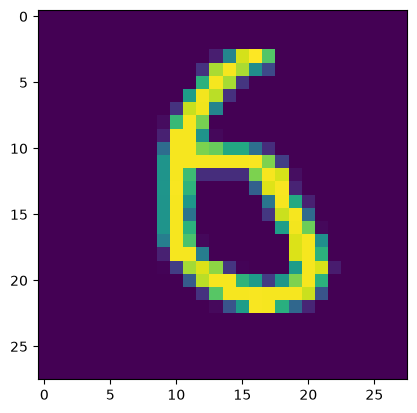

In [55]:
# Random image taken 

x_test[786]
plt.imshow(x_test[786])
plt.show()

In [57]:
np.argmax(y_pred[786])

np.int64(6)

In [60]:
# Save the intelligence file

model.save("Digits_intel.h5")

# Test with outside Data 

In [61]:
# Downloaded the image from the internet

image_path = r"R:\Learning\Deep Learning\01_MNSIT_Dataset\Digit_image_2.png"
image = Image.open(image_path)
image.size


(148, 113)

In [62]:
# Convert the size internally , since we trained the model with 28*28 images only

new_image = image.resize(size=(28,28))
new_image.size

(28, 28)

In [63]:
# Conver the colour image into grey scale , since we trained all images are in a grey scale

new_image.mode

'RGBA'

In [66]:
final_image = new_image.convert(mode="L")

In [67]:
final_image.mode

'L'

In [69]:
final_image

In [81]:
# Let's do the prediction

digits_brain = load_model("Digits_intel.h5")

def predict_image(image):
    fin = np.array(image)
    image = 255 - fin   # Invert the colours if it is contains the white background
    image = image/255.0
    imag = np.expand_dims(a=image,axis=0)
    print(imag.shape)
    prediction = digits_brain.predict(imag)
    return np.argmax(prediction)
    

In [82]:
predict_image(final_image)

(1, 28, 28)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


np.int64(2)